# VIR-Bench: одно видео понятным языком и статистика датасета

**Цель:** разобрать реальную строку разметки до списка мест с таймкодами и понять, какие данные полезны для проекта маршрутов из коротких видео.

Ноутбук читает локальный архив аннотаций, показывает видео `0Vjufc6rhH8` (строка 158 в текущем test) и считает статистику отдельно для `test` и `validation`. Модели, платные API и загрузка исходных видео не используются. Ячейки нужно выполнять сверху вниз.

## Окружение и данные

Проверенное окружение: Python 3.12; pandas 2.2.2, pyarrow 17.0.0, matplotlib 3.10.8, ipykernel 6.29.4. При подготовке отдельного окружения зависимости можно установить **в терминале**:

```powershell
py -m pip install pandas==2.2.2 pyarrow==17.0.0 matplotlib==3.10.8 ipykernel==6.29.4
```

Исходники: [VIR-Bench на GitHub](https://github.com/nlp-waseda/VIR-Bench), [статья](https://arxiv.org/abs/2509.19002). Исследованный snapshot репозитория: `048b0457c6ef690cbced99ab9eff2d8eee79b869`. Нужен его файл `data/data.zip` (Parquet-аннотации). Положите архив в `data/raw/virbench/data.zip` относительно корня reels-router или задайте `ARCHIVE_OVERRIDE` ниже. Также поддерживается уже существующий соседний каталог `references/VIR-Bench`.

Архив и видео не включены в репозиторий. Условия использования данных рассматриваются отдельно от лицензии кода: см. раздел Release Policy статьи перед распространением данных или сохранённых примеров разметки. Здесь анализ выполняется локально.

**Ограничения:** это разметка туристических видео о Японии, а не готовый корпус русскоязычных Reels. В архиве нет транскрипций, OCR, подписей публикаций и видеофайлов. Названия мест на английском/японском не определяют язык речи.



In [1]:
import ast
import hashlib
import io
import math
import platform
from datetime import datetime, timezone
from html import escape
from importlib.metadata import version
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import HTML, Markdown, display

pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 120})

# При необходимости задайте свой путь: Path(r"C:\данные\VIR-Bench\data.zip").
ARCHIVE_OVERRIDE = None
EXAMPLE_VIDEO_ID = "0Vjufc6rhH8"
FOCUS_NODE_ID = "6"

if ARCHIVE_OVERRIDE is not None:
    DATA_ZIP = Path(ARCHIVE_OVERRIDE).expanduser().resolve()
else:
    candidates = [
        base / relative
        for base in [Path.cwd(), *Path.cwd().parents]
        for relative in (
            "data/raw/virbench/data.zip",
            "references/VIR-Bench/data/data.zip",
        )
    ]
    DATA_ZIP = next((path for path in candidates if path.is_file()), None)

if DATA_ZIP is None or not DATA_ZIP.is_file():
    raise FileNotFoundError(
        "Не найден data.zip. Поместите архив в data/raw/virbench/ "
        "или задайте ARCHIVE_OVERRIDE в этой ячейке."
    )

print("Python:", platform.python_version())
print("Библиотеки:", {name: version(name) for name in ("pandas", "pyarrow", "matplotlib", "ipykernel")})
print("Выполнение (UTC):", datetime.now(timezone.utc).isoformat(timespec="seconds"))

Python: 3.12.3
Библиотеки: {'pandas': '2.2.2', 'pyarrow': '17.0.0', 'matplotlib': '3.10.8', 'ipykernel': '6.29.4'}
Выполнение (UTC): 2026-10-25T08:40:22+00:00


## 1. Что лежит в архиве

Одна строка Parquet соответствует одному видео. Поле `graph` содержит узлы (регионы, города, места) и связи между ними. Внутри `nodes` и `edges` значения хранятся параллельными массивами: элементы с одинаковым индексом образуют одну запись. Сначала проверяем состав архива и фиксируем его SHA-256 для воспроизводимости.

In [2]:
with DATA_ZIP.open("rb") as stream:
    archive_sha256 = hashlib.file_digest(stream, "sha256").hexdigest()

raw_splits = {}
archive_rows = []
with ZipFile(DATA_ZIP) as archive:
    for split in ("test", "validation"):
        member = f"data/{split}-00000-of-00001.parquet"
        table = pq.read_table(io.BytesIO(archive.read(member)))
        raw_splits[split] = table.to_pylist()
        archive_rows.append({
            "split": split,
            "строк / видео": table.num_rows,
            "размер Parquet, MiB": round(archive.getinfo(member).file_size / 2**20, 2),
            "колонки": ", ".join(table.column_names),
        })

print("SHA-256 data.zip:", archive_sha256)
print("Размер архива, MiB:", round(DATA_ZIP.stat().st_size / 2**20, 2))
display(pd.DataFrame(archive_rows).set_index("split"))
example_graph = raw_splits["test"][0]["graph"]
display(pd.DataFrame([
    {"часть графа": part, "поля": ", ".join(arrays)}
    for part, arrays in example_graph.items()
]))

SHA-256 data.zip: c735ceaf3f9c2d49fd9125954f866c36964ab24fef06ed7c12bfa3a6330ef466
Размер архива, MiB: 58.22


,строк / видео,"размер Parquet, MiB",колонки
split,,,
test,200,71.13,"video_id, graph"
validation,4,0.83,"video_id, graph"


,часть графа,поля
0,nodes,"id, type, display_name, attributes"
1,edges,"source, target, type, attributes"


## 2. Из вложенного графа — в обычные таблицы

Получаем три уровня: `videos_df` — видео, `nodes_df` — все узлы, `poi_df` — только места; связи храним в `edges_df`. `node_id` уникален только внутри видео, поэтому ключ включает `split`, `video_id`, `node_id`.

`display_name` и `attributes` записаны как строковые представления Python-словарей. Читаем их через `ast.literal_eval`, без исполнения кода. Из больших ответов Places оставляем несколько полезных полей; отзывы и фотографии не выводим.

Поле `description` — аннотация места (ссылка на карту или название с категорией), **не** подпись к видео и **не** транскрипция. `start` / `end` — секунды внутри смонтированного видео. Их разность далее называется длительностью размеченного фрагмента.

In [3]:
def parse_mapping(value):
    """Прочитать словарь, записанный строкой, без eval и pickle."""
    parsed = ast.literal_eval(value) if isinstance(value, str) else value
    if not isinstance(parsed, dict):
        raise TypeError(f"Ожидался словарь, получен {type(parsed).__name__}")
    return parsed


def parallel_records(arrays):
    """Проверить длины и собрать записи из параллельных массивов."""
    lengths = {field: len(values) for field, values in arrays.items()}
    if len(set(lengths.values())) != 1:
        raise ValueError(f"Несогласованные длины полей: {lengths}")
    return [dict(zip(arrays, values)) for values in zip(*arrays.values())]


def timestamp(seconds):
    """Таймкод без потери десятых секунды; часы показываем при необходимости."""
    if pd.isna(seconds):
        return "нет данных"
    tenths = round(float(seconds) * 10)
    hours, remainder = divmod(tenths, 36_000)
    minutes, remainder = divmod(remainder, 600)
    seconds, fraction = divmod(remainder, 10)
    prefix = f"{hours:02d}:" if hours else ""
    return f"{prefix}{minutes:02d}:{seconds:02d}.{fraction}"

In [4]:
node_rows, edge_rows, video_rows = [], [], []

for split, records in raw_splits.items():
    for row_index, record in enumerate(records):
        video_id = record["video_id"]
        common = {"split": split, "video_id": video_id}
        nodes = parallel_records(record["graph"]["nodes"])
        edges = parallel_records(record["graph"]["edges"])
        video_rows.append({**common, "row_index": row_index, "n_nodes": len(nodes), "n_edges": len(edges)})

        for node in nodes:
            names = parse_mapping(node["display_name"])
            attrs = parse_mapping(node["attributes"])
            row = {
                **common, "node_id": str(node["id"]), "node_type": node["type"],
                "name_en": names.get("en"), "name_ja": names.get("ja"),
                "name": names.get("en") or names.get("ja") or "Без названия",
            }
            if node["type"] == "POI":
                description = attrs.get("parsed_description") or {}
                details = attrs.get("details_parsed") or {}
                location = details.get("location") or {}
                address = details.get("formattedAddress") or {}
                raw_details = attrs.get("details_raw") or {}
                raw_en = raw_details.get("en") or {}
                raw_ja = raw_details.get("ja") or {}
                # Один place_id на узел: языковые версии не считаются двумя местами.
                row.update({
                    "start_s": attrs.get("start"), "end_s": attrs.get("end"),
                    "annotation_description": attrs.get("description", ""),
                    "maps_url": description.get("url", ""),
                    "annotation_category": description.get("category", ""),
                    "primary_type": details.get("primaryType", ""),
                    "is_unknown": description.get("is_unknown"),
                    "is_store_unknown": description.get("is_store_unknown"),
                    "has_details": bool(details),
                    "address": address.get("en") or address.get("ja") or "",
                    "latitude": location.get("latitude"), "longitude": location.get("longitude"),
                    "place_id": raw_en.get("id") or raw_ja.get("id"),
                    "cached_rating": raw_en.get("rating", raw_ja.get("rating")),
                    "cached_review_count": raw_en.get("userRatingCount", raw_ja.get("userRatingCount")),
                    "cached_business_status": raw_en.get("businessStatus") or raw_ja.get("businessStatus"),
                })
            node_rows.append(row)

        for edge in edges:
            edge_rows.append({
                **common, "source": str(edge["source"]), "target": str(edge["target"]),
                "edge_type": edge["type"],
            })

nodes_df = pd.DataFrame(node_rows)
edges_df = pd.DataFrame(edge_rows)
poi_df = nodes_df.loc[nodes_df["node_type"].eq("POI")].copy()
for column in ("start_s", "end_s", "latitude", "longitude"):
    poi_df[column] = pd.to_numeric(poi_df[column], errors="raise")
poi_df["fragment_s"] = poi_df["end_s"] - poi_df["start_s"]
poi_df["has_coordinates"] = poi_df[["latitude", "longitude"]].notna().all(axis=1)
poi_df["has_address"] = poi_df["address"].fillna("").str.strip().ne("")
poi_df["category"] = poi_df["annotation_category"].replace("", pd.NA).fillna("(нет категории)")

video_poi = poi_df.groupby(["split", "video_id"]).agg(
    n_poi=("node_id", "size"), annotated_until_s=("end_s", "max")
).reset_index()
videos_df = pd.DataFrame(video_rows).merge(video_poi, on=["split", "video_id"], how="left", validate="one_to_one")
videos_df["n_poi"] = videos_df["n_poi"].fillna(0).astype(int)
print(f"Таблицы готовы: {len(videos_df)} видео, {len(nodes_df)} узлов, {len(poi_df)} POI, {len(edges_df)} связей.")

Таблицы готовы: 204 видео, 4968 узлов, 3633 POI, 7841 связей.


### Единицы подсчёта

Один POI-узел — одно размеченное появление места в видео. Одно и то же физическое место может встречаться в нескольких видео или повторно в одном видео. Поэтому число POI-узлов и число уникальных Places ID отвечают на разные вопросы. Английское и японское имя одного узла также не создают два объекта.

In [5]:
split_summary = videos_df.groupby("split").agg(
    videos=("video_id", "size"), nodes=("n_nodes", "sum"),
    edges=("n_edges", "sum"), poi=("n_poi", "sum"),
    poi_min=("n_poi", "min"), poi_median=("n_poi", "median"),
    poi_mean=("n_poi", "mean"), poi_max=("n_poi", "max"),
)
display(split_summary.round(2).rename(columns={
    "videos": "видео", "nodes": "узлов", "edges": "связей", "poi": "POI-узлов",
    "poi_min": "POI: min", "poi_median": "POI: медиана", "poi_mean": "POI: среднее", "poi_max": "POI: max",
}))
display(pd.crosstab(nodes_df["split"], nodes_df["node_type"]))
display(pd.crosstab(edges_df["split"], edges_df["edge_type"]))

,видео,узлов,связей,POI-узлов,POI: min,POI: медиана,POI: среднее,POI: max
split,,,,,,,,
test,200,4908,7755,3594,6,15.0,17.97,72
validation,4,60,86,39,6,10.5,9.75,12


node_type,CITY,POI,PREFECTURE,ROOT
split,,,,
test,780,3594,334,200
validation,13,39,4,4


edge_type,INCLUSION,OVERLAP,TRANSITION
split,,,
test,4700,8,3047
validation,55,1,30


## 3. Одно видео человеческим языком

Берём ранее случайно выбранное видео `0Vjufc6rhH8`. Теперь ID зафиксирован, чтобы пример был воспроизводим; для другого видео измените `EXAMPLE_VIDEO_ID` в начале ноутбука. Сначала отделим доступную разметку от отсутствующих каналов информации, затем покажем места по порядку появления.

Ссылка ведёт на исходный **YouTube-влог**, а не на восстановленный Reels. Доступность видео не проверяется; его название, речь и визуальное содержание из этого архива восстановить нельзя.

In [6]:
sample_video = videos_df.loc[
    videos_df["split"].eq("test") & videos_df["video_id"].eq(EXAMPLE_VIDEO_ID)
]
if len(sample_video) != 1:
    raise ValueError("EXAMPLE_VIDEO_ID должен однозначно находиться в test.")
sample_video = sample_video.iloc[0]
sample_nodes = nodes_df.loc[nodes_df["split"].eq("test") & nodes_df["video_id"].eq(EXAMPLE_VIDEO_ID)]
sample_poi = poi_df.loc[poi_df["split"].eq("test") & poi_df["video_id"].eq(EXAMPLE_VIDEO_ID)].sort_values("start_s")
sample_edges = edges_df.loc[edges_df["split"].eq("test") & edges_df["video_id"].eq(EXAMPLE_VIDEO_ID)]
video_url = f"https://www.youtube.com/watch?v={EXAMPLE_VIDEO_ID}"
regions = ", ".join(sample_nodes.loc[sample_nodes["node_type"].eq("PREFECTURE"), "name"])
cities = ", ".join(sample_nodes.loc[sample_nodes["node_type"].eq("CITY"), "name"])

display(Markdown(
    f"### Видео `{EXAMPLE_VIDEO_ID}`\n\n"
    f"[Открыть исходное видео]({video_url}) · строка test: **{sample_video['row_index']}** (с нуля).\n\n"
    f"По разметке: **{regions} → {cities}**. "
    f"Мест: **{len(sample_poi)}**; всего узлов: **{sample_video['n_nodes']}**; "
    f"связей: **{sample_video['n_edges']}**. Последняя размеченная отметка: "
    f"**{timestamp(sample_video['annotated_until_s'])}**, не обязательно конец видео."
))
display(pd.DataFrame([
    ["Источник видео", "video_id → ссылка на YouTube; видеофайл отсутствует"],
    ["ASR / транскрипция речи", "Отсутствует"],
    ["Субтитры", "Отсутствуют"],
    ["OCR: надписи на кадрах", "Отсутствует"],
    ["Название и подпись публикации", "Отсутствуют"],
    ["Разметка мест", "Есть: имена, start/end, категория, связи графа"],
    ["Адреса / координаты", "Есть у части POI: сохранённые поля Places"],
    ["description", "Ссылка на карту либо описание места аннотатором; не слова из видео"],
], columns=["Что хотелось бы получить", "Что реально есть в этой строке"]))

### Видео `0Vjufc6rhH8`

[Открыть исходное видео](https://www.youtube.com/watch?v=0Vjufc6rhH8) · строка test: **158** (с нуля).

По разметке: **Shizuoka → Numazu**. Мест: **18**; всего узлов: **21**; связей: **34**. Последняя размеченная отметка: **15:41.0**, не обязательно конец видео.

,Что хотелось бы получить,Что реально есть в этой строке
0,Источник видео,video_id → ссылка на YouTube; видеофайл отсутствует
1,ASR / транскрипция речи,Отсутствует
2,Субтитры,Отсутствуют
3,OCR: надписи на кадрах,Отсутствует
4,Название и подпись публикации,Отсутствуют
5,Разметка мест,"Есть: имена, start/end, категория, связи графа"
6,Адреса / координаты,Есть у части POI: сохранённые поля Places
7,description,Ссылка на карту либо описание места аннотатором; не слова из видео


In [7]:
human_poi = pd.DataFrame({
    "ID": sample_poi["node_id"],
    "С": sample_poi["start_s"].map(timestamp),
    "До": sample_poi["end_s"].map(timestamp),
    "Фрагмент, с": sample_poi["fragment_s"].round(1),
    "Место": sample_poi["name"],
    "Категория разметки": sample_poi["category"],
    "Координаты": sample_poi["has_coordinates"].map({True: "есть", False: "нет"}),
})
# Экранируем текст датасета; HTML добавляем только для созданных здесь ссылок.
human_html = human_poi.map(lambda value: escape(str(value)))
human_html["Видео с этого момента"] = [
    f'<a href="{escape(video_url, quote=True)}&amp;t={math.floor(start)}s">▶ {timestamp(start)}</a>'
    for start in sample_poi["start_s"]
]
display(HTML(human_html.to_html(index=False, escape=False)))
display(Markdown(
    "Таймкод в ссылке округлён вниз до целой секунды; в таблице сохранены десятые. "
    "Пустое английское имя заменено японским. Категории оставлены как в разметке, "
    "поэтому необычные значения не исправлены автоматически."
))

ID,С,До,"Фрагмент, с",Место,Категория разметки,Координаты,Видео с этого момента
3,00:07.9,01:49.0,101.1,Numazu Station,train_station,есть,▶ 00:07.9
4,00:54.6,01:49.0,54.4,Numazu Tourism Association (NPO corporation),tourist_information_center,есть,▶ 00:54.6
5,02:13.5,02:25.0,11.5,井上靖の母子像 (井上靖文学碑),historical_landmark,есть,▶ 02:13.5
6,03:42.8,04:10.0,27.2,SUN! SUN! SUNSHINE CAFE,cafe,есть,▶ 03:42.8
7,04:26.7,04:52.0,25.3,Animate Numazu,book_store,есть,▶ 04:26.7
8,05:02.6,05:45.0,42.4,Gamers Numazu store,store,есть,▶ 05:02.6
9,05:48.4,07:19.0,90.6,Numazu Nakamise Shopping Street,shopping_mall,есть,▶ 05:48.4
10,06:23.4,07:19.0,55.6,マルサン書店仲見世店,book_store,нет,▶ 06:23.4
11,08:06.4,08:34.0,27.6,Tsuji Photography,(нет категории),есть,▶ 08:06.4
12,08:39.2,09:20.0,40.8,Onari Bridge,(нет категории),есть,▶ 08:39.2


Таймкод в ссылке округлён вниз до целой секунды; в таблице сохранены десятые. Пустое английское имя заменено японским. Категории оставлены как в разметке, поэтому необычные значения не исправлены автоматически.

### Карточка одного места: что можно получить для маршрута

Ниже подробно разбирается POI `6` — кафе из этого видео. Название, интервал и категория относятся к разметке; адрес, координаты, рейтинг и статус бизнеса взяты из сохранённого ответа Places. Это исторический снимок, его актуальность здесь не проверяется. Для другого POI измените `FOCUS_NODE_ID` в начале.

In [8]:
focus = sample_poi.loc[sample_poi["node_id"].eq(FOCUS_NODE_ID)]
if len(focus) != 1:
    raise ValueError("FOCUS_NODE_ID должен указывать на один POI выбранного видео.")
focus = focus.iloc[0]
coordinates = (
    f"{focus['latitude']:.7f}, {focus['longitude']:.7f}"
    if focus["has_coordinates"] else "отсутствуют"
)
rating = "нет данных" if pd.isna(focus["cached_rating"]) else f"{focus['cached_rating']:g}"
review_count = "нет данных" if pd.isna(focus["cached_review_count"]) else f"{focus['cached_review_count']:g}"
card = pd.DataFrame([
    ["Название EN", focus["name_en"], "разметка"],
    ["Название JA", focus["name_ja"], "разметка"],
    ["Фрагмент видео", f"{timestamp(focus['start_s'])} — {timestamp(focus['end_s'])}", "разметка"],
    ["Категория", focus["category"], "разметка"],
    ["description", focus["annotation_description"], "аннотация места"],
    ["Адрес", focus["address"] or "отсутствует", "сохранённый Places"],
    ["Координаты: широта, долгота", coordinates, "сохранённый Places"],
    ["Places ID", focus["place_id"], "сохранённый Places"],
    ["Рейтинг / число оценок", f"{rating} / {review_count}", "сохранённый Places"],
    ["Статус бизнеса", focus["cached_business_status"], "сохранённый Places"],
], columns=["Поле", "Значение", "Происхождение"]).fillna("нет данных")
display(HTML(card.to_html(index=False, escape=True)))
status = focus["cached_business_status"]
status_note = (
    f"Статус в сохранённом снимке: **{status}**. "
    if pd.notna(status) else "Статус бизнеса в снимке отсутствует. "
)
display(Markdown(
    status_note + "Перед рекомендацией места нужно обновить его статус. "
    "Из аннотаций нельзя узнать текущие часы работы, наличие мест или актуальный рейтинг."
))



Поле,Значение,Происхождение
Название EN,SUN! SUN! SUNSHINE CAFE,разметка
Название JA,ラブライブ！サンシャイン!! × 雄大 SUN!SUN! サンシャインCafe,разметка
Фрагмент видео,03:42.8 — 04:10.0,разметка
Категория,cafe,разметка
description,https://maps.app.goo.gl/vfdCcsbzJCxizzzY7,аннотация места
Адрес,"3-chōme-1-1 Ōtemachi, Numazu, Shizuoka 410-0801, Japan",сохранённый Places
"Координаты: широта, долгота","35.1019681, 138.8596860",сохранённый Places
Places ID,ChIJASL3qGCFGWARKfCZaYW-KFI,сохранённый Places
Рейтинг / число оценок,4.3 / 674,сохранённый Places
Статус бизнеса,CLOSED_PERMANENTLY,сохранённый Places


Статус в сохранённом снимке: **CLOSED_PERMANENTLY**. Перед рекомендацией места нужно обновить его статус. Из аннотаций нельзя узнать текущие часы работы, наличие мест или актуальный рейтинг.

### Где каждое место появляется в видео

Полосы показывают размеченные интервалы на шкале видео. Пересечения возможны: например, в одном фрагменте размечены станция и туристический центр внутри неё. Их нельзя складывать, чтобы получить длину видео или длительность путешествия. Полные названия есть в таблице выше; японские названия на графике заменены ссылкой на ID, чтобы не требовалась установка дополнительных шрифтов.

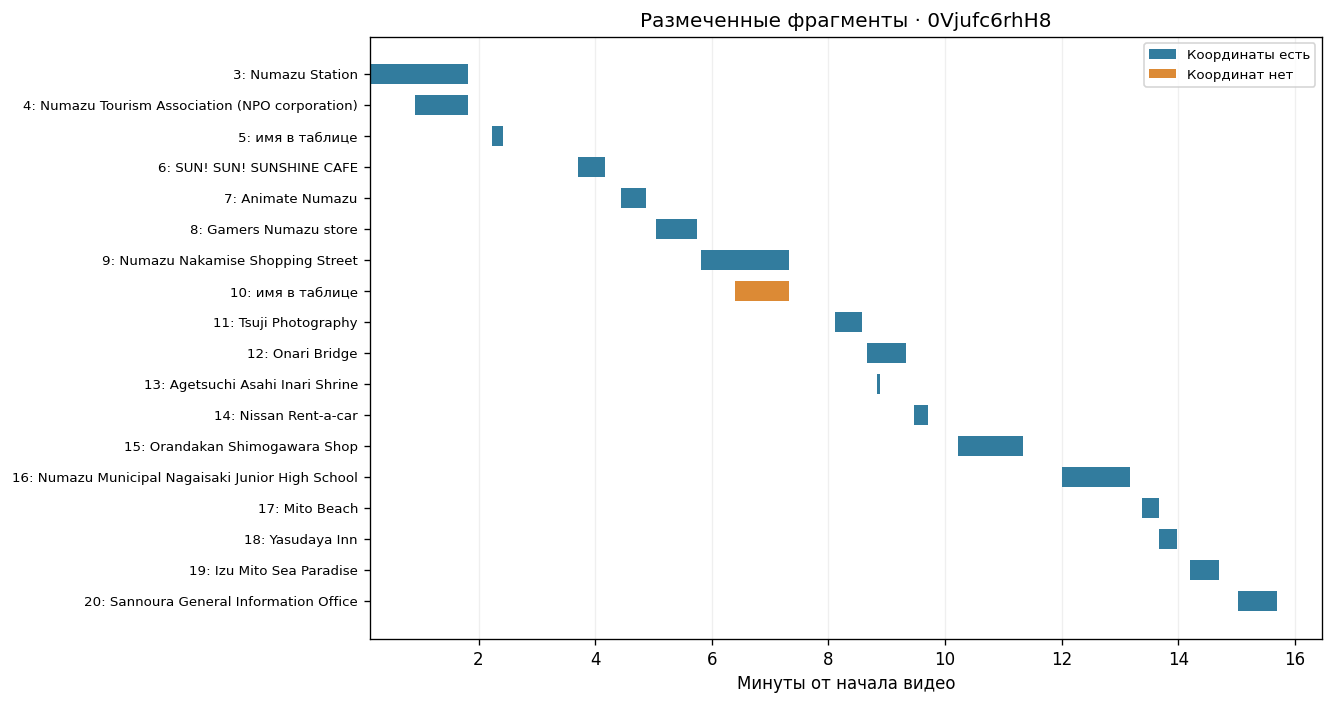

In [9]:
labels = []
for row in sample_poi.itertuples():
    label = row.name_en if isinstance(row.name_en, str) and row.name_en else "имя в таблице"
    if any("\u3000" <= character <= "\u9fff" for character in label):
        label = "имя в таблице"
    labels.append(f"{row.node_id}: {label}")

fig, ax = plt.subplots(figsize=(11, max(5, len(sample_poi) * 0.32)), layout="constrained")
for has_coordinates, color, legend_label in (
    (True, "#327c9e", "Координаты есть"), (False, "#dc8a35", "Координат нет")
):
    positions = [i for i, value in enumerate(sample_poi["has_coordinates"]) if value == has_coordinates]
    subset = sample_poi.iloc[positions]
    ax.barh(positions, subset["fragment_s"] / 60, left=subset["start_s"] / 60,
            color=color, height=0.65, label=legend_label)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Минуты от начала видео")
ax.set_title(f"Размеченные фрагменты · {EXAMPLE_VIDEO_ID}")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="upper right", fontsize=8)
plt.show()
plt.close(fig)

### Что означают связи

- `INCLUSION` задаёт иерархию в разметке: регион → город → POI, иногда POI → вложенный POI. Это утверждение аннотации, а не отдельная географическая проверка.
- `TRANSITION` задаёт переход между последовательными посещениями на одном уровне иерархии. Порядок взят из разметки видео; это не оптимизированный маршрут и не оценка времени дороги.
- `OVERLAP` встречается в сыром архиве; здесь сохраняем его отдельно. В [преобразовании для edge prediction](https://github.com/nlp-waseda/VIR-Bench/blob/048b0457c6ef690cbced99ab9eff2d8eee79b869/lmms-eval/lmms_eval/tasks/virbench/utils.py#L255) такие рёбра пропускаются.

Ниже показаны переходы и связи вложенности между POI выбранного видео. Остальные связи иерархии остаются в `sample_edges`.

In [10]:
names_by_id = sample_nodes.set_index("node_id")["name"].to_dict()
poi_ids = set(sample_poi["node_id"])
interesting_edges = sample_edges.loc[
    sample_edges["edge_type"].eq("TRANSITION")
    | (sample_edges["source"].isin(poi_ids) & sample_edges["target"].isin(poi_ids))
].copy()
interesting_edges["Откуда"] = interesting_edges["source"].map(
    lambda node_id: f"{node_id}: {names_by_id[node_id]}"
)
interesting_edges["Куда"] = interesting_edges["target"].map(
    lambda node_id: f"{node_id}: {names_by_id[node_id]}"
)
display(HTML(interesting_edges[["Откуда", "edge_type", "Куда"]].rename(
    columns={"edge_type": "Связь"}
).to_html(index=False, escape=True)))

Откуда,Связь,Куда
3: Numazu Station,INCLUSION,4: Numazu Tourism Association (NPO corporation)
3: Numazu Station,TRANSITION,5: 井上靖の母子像 (井上靖文学碑)
5: 井上靖の母子像 (井上靖文学碑),TRANSITION,6: SUN! SUN! SUNSHINE CAFE
6: SUN! SUN! SUNSHINE CAFE,TRANSITION,7: Animate Numazu
7: Animate Numazu,TRANSITION,8: Gamers Numazu store
8: Gamers Numazu store,TRANSITION,9: Numazu Nakamise Shopping Street
9: Numazu Nakamise Shopping Street,INCLUSION,10: マルサン書店仲見世店
9: Numazu Nakamise Shopping Street,TRANSITION,11: Tsuji Photography
11: Tsuji Photography,TRANSITION,12: Onari Bridge
12: Onari Bridge,INCLUSION,13: Agetsuchi Asahi Inari Shrine


## 4. Размер примеров и полнота данных

Сводные таблицы включают оба split. Графики распределений строятся по **test**: четыре видео validation слишком мало для устойчивой оценки распределений. Это описательный анализ разметки; по test не выбираем модели и гиперпараметры.

Разделяем длительность **POI-фрагмента** и `max(end)` по видео — **последнюю размеченную отметку**. Настоящая длина видео и реальное время путешествия в архиве отсутствуют. В таблице ниже число уникальных Places ID считается только среди заполненных ID.

,уникальных Places ID,POI с Places ID,"фрагмент: min, с","фрагмент: медиана, с","фрагмент: p90, с","фрагмент: max, с","max(end): медиана, мин"
split,,,,,,,
test,2720,3505,0.4,27.2,124.96,857.3,16.26
validation,38,38,10.1,42.9,186.96,434.7,16.34


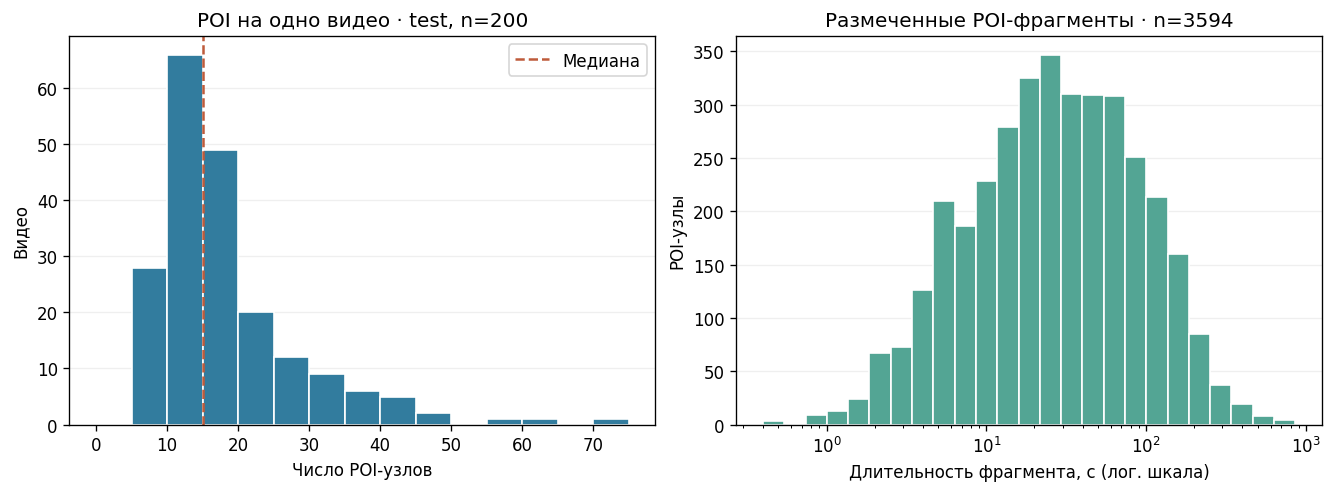

In [11]:
test_poi = poi_df.loc[poi_df["split"].eq("test")].copy()
test_videos = videos_df.loc[videos_df["split"].eq("test")].copy()
duration_summary = []
for split, group in poi_df.groupby("split"):
    video_group = videos_df.loc[videos_df["split"].eq(split)]
    duration_summary.append({
        "split": split,
        "уникальных Places ID": group["place_id"].nunique(),
        "POI с Places ID": group["place_id"].notna().sum(),
        "фрагмент: min, с": group["fragment_s"].min(),
        "фрагмент: медиана, с": group["fragment_s"].median(),
        "фрагмент: p90, с": group["fragment_s"].quantile(0.9),
        "фрагмент: max, с": group["fragment_s"].max(),
        "max(end): медиана, мин": video_group["annotated_until_s"].median() / 60,
    })
display(pd.DataFrame(duration_summary).set_index("split").round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].hist(test_videos["n_poi"], bins=range(0, int(test_videos["n_poi"].max()) + 6, 5),
             color="#327c9e", edgecolor="white")
axes[0].axvline(test_videos["n_poi"].median(), color="#be5b3b", linestyle="--", label="Медиана")
axes[0].set(title=f"POI на одно видео · test, n={len(test_videos)}", xlabel="Число POI-узлов", ylabel="Видео")
axes[0].legend()

fragment_values = test_poi.loc[test_poi["fragment_s"].gt(0), "fragment_s"]
log_min, log_max = math.log10(fragment_values.min()), math.log10(fragment_values.max())
duration_bins = [10 ** (log_min + i * (log_max - log_min) / 25) for i in range(26)]
# Явные крайние границы исключают потерю min/max из-за округления float.
duration_bins[0], duration_bins[-1] = fragment_values.min(), fragment_values.max()
axes[1].hist(fragment_values, bins=duration_bins, color="#53a594", edgecolor="white")
axes[1].set_xscale("log")
axes[1].set(title=f"Размеченные POI-фрагменты · n={len(fragment_values)}",
            xlabel="Длительность фрагмента, с (лог. шкала)", ylabel="POI-узлы")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
plt.show()
plt.close(fig)

### Какие поля заполнены

Доли считаются от всех POI-узлов соответствующего split. «Координаты есть» означает наличие обеих числовых координат, но ещё не подтверждает их правильность. Категория берётся из `parsed_description.category`; её не подменяем `primaryType` из Places. Признаки `is_unknown` и `is_store_unknown` показываем отдельно: они могут пересекаться и не заменяют проверку пропусков.

In [12]:
def nonempty(series):
    return series.fillna("").astype(str).str.strip().ne("")


coverage_rows = []
flag_rows = []
for split, group in poi_df.groupby("split"):
    fields = {
        "Имя EN": nonempty(group["name_en"]),
        "Имя JA": nonempty(group["name_ja"]),
        "Категория разметки": nonempty(group["annotation_category"]),
        "Таймкоды start и end": group[["start_s", "end_s"]].notna().all(axis=1),
        "Ссылка на карту": nonempty(group["maps_url"]),
        "Адрес": group["has_address"],
        "Координаты": group["has_coordinates"],
        "Places ID": nonempty(group["place_id"]),
    }
    for field, present in fields.items():
        coverage_rows.append({
            "split": split, "поле": field, "всего POI": len(group),
            "есть": int(present.sum()), "нет": int((~present).sum()), "есть, %": 100 * present.mean(),
        })
    flag_rows.append({
        "split": split,
        "is_unknown": group["is_unknown"].eq(True).sum(),
        "is_store_unknown": group["is_store_unknown"].eq(True).sum(),
        "оба флага": (group["is_unknown"].eq(True) & group["is_store_unknown"].eq(True)).sum(),
    })
coverage_df = pd.DataFrame(coverage_rows)
display(coverage_df.set_index(["split", "поле"]).round(2))
display(pd.DataFrame(flag_rows).set_index("split"))

всего POI  есть  нет  есть, %
split      поле                                               
test       Имя EN                     3594  3585    9    99.75
           Имя JA                     3594  3587    7    99.81
           Категория разметки         3594  3298  296    91.76
           Таймкоды start и end       3594  3594    0   100.00
           Ссылка на карту            3594  3505   89    97.52
           Адрес                      3594  3505   89    97.52
           Координаты                 3594  3505   89    97.52
           Places ID                  3594  3505   89    97.52
validation Имя EN                       39    39    0   100.00
           Имя JA                       39    39    0   100.00
           Категория разметки           39    39    0   100.00
           Таймкоды start и end         39    39    0   100.00
           Ссылка на карту              39    38    1    97.44
           Адрес                        39    38    1    97.44
           Координаты                   39    38    1    97.44
           Places ID                    39    38    1    97.44

,is_unknown,is_store_unknown,оба флага
split,,,
test,73,36,0
validation,1,1,0


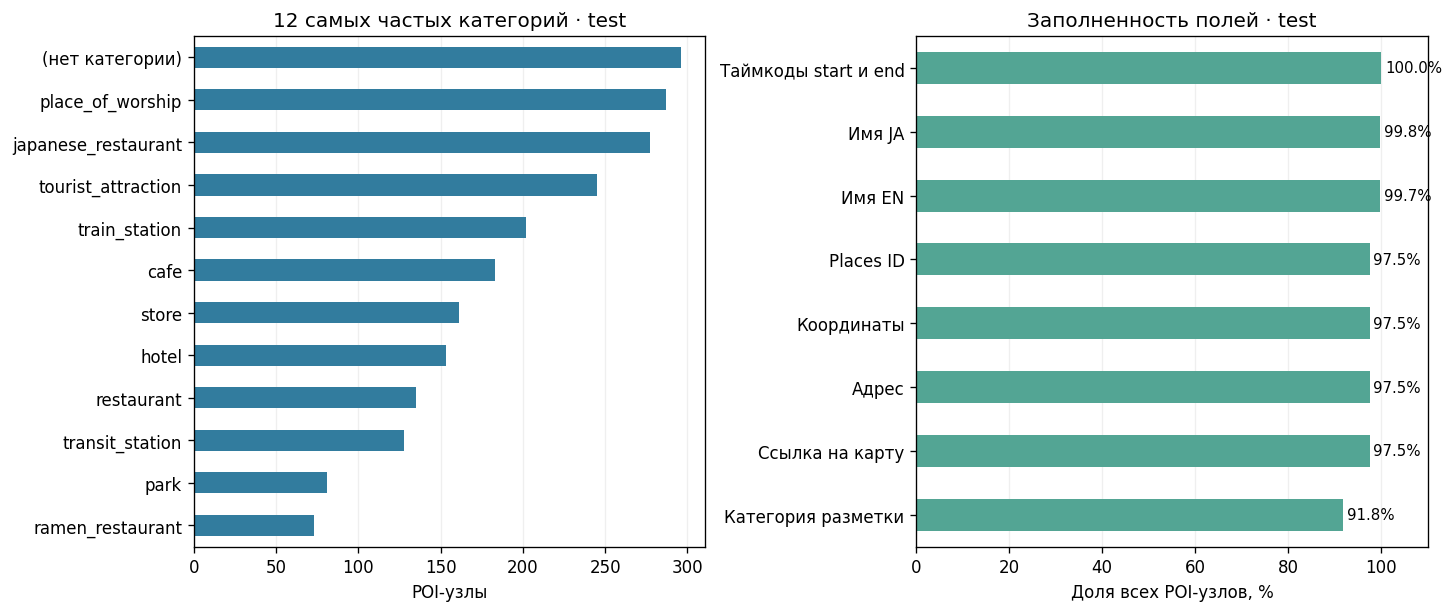

In [13]:
top_categories = test_poi["category"].value_counts().head(12).sort_values()
test_coverage = coverage_df.loc[coverage_df["split"].eq("test")].set_index("поле")["есть, %"].sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
top_categories.plot.barh(ax=axes[0], color="#327c9e")
axes[0].set(title="12 самых частых категорий · test", xlabel="POI-узлы", ylabel="")
test_coverage.plot.barh(ax=axes[1], color="#53a594")
axes[1].set(title="Заполненность полей · test", xlabel="Доля всех POI-узлов, %", ylabel="", xlim=(0, 110))
for position, value in enumerate(test_coverage):
    axes[1].text(value + 0.8, position, f"{value:.1f}%", va="center", fontsize=9)
for ax in axes:
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
plt.show()
plt.close(fig)

## 5. География и повторяющиеся места

Слева — частота **исходных строк названий** префектур: одно видео может относиться к нескольким регионам. Варианты вроде названия с суффиксом `Prefecture` и без него пока не объединяем. Число разных строк нельзя выдавать за число реальных административных регионов.

Справа — диаграмма координат POI, без картографической подложки и внешних сервисов. Каждая точка соответствует узлу; популярные места могут повторяться. Плотность точек отражает состав этой выборки, а не полноту туристических мест Японии.

Разных строк названий префектур в test: 51
POI с координатами: 3505 из 3594


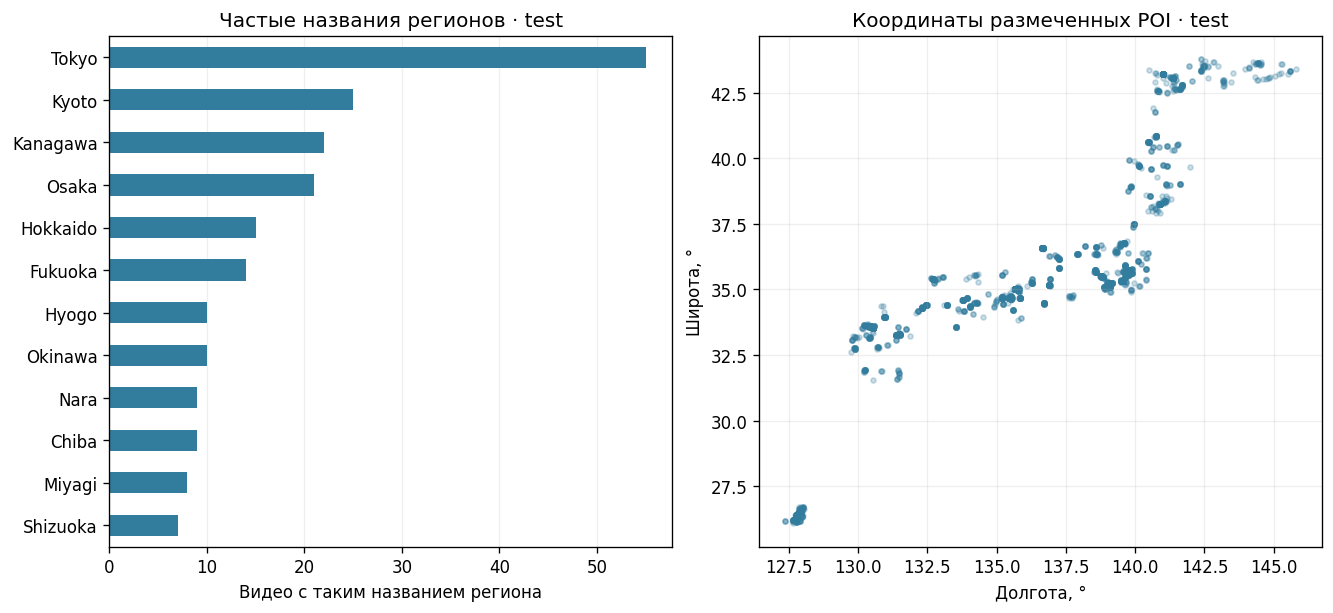

,пример названия,POI-узлов,видео
place_id,,,
ChIJC3Cf2PuLGGAROO00ukl8JwA,Tokyo Station,17,15
ChIJ7wKLka4IAWARCByidG5EGrY,Kyoto Station,17,12
ChIJK9EM68qLGGARacmu4KJj5SA,Shibuya Scramble Crossing,15,12
ChIJdbP55seRQTURkIu5RT0r4i4,Hakata Station,14,11
ChIJIW0uPRUPAWAR6eI6dRzKGns,Fushimi Inari Taisha,11,11
ChIJrYtcv-urAWAR3XzWvXv8n_s,Arashiyama Bamboo Forest,11,11
ChIJ8T1GpMGOGGARDYGSgpooDWw,Sensō-ji,11,10
ChIJB_vchdMIAWARujTEUIZlr2I,Kiyomizu-dera,11,10
ChIJT8uMzZwIAWARnGzsARCjnrY,Nishiki Market,8,8


Places ID, встречающихся более чем в одном видео: 276


In [14]:
prefecture_mentions = nodes_df.loc[
    nodes_df["split"].eq("test") & nodes_df["node_type"].eq("PREFECTURE")
].drop_duplicates(["video_id", "name"])
prefecture_counts = prefecture_mentions["name"].value_counts()
mapped_poi = test_poi.loc[test_poi["has_coordinates"]]
print("Разных строк названий префектур в test:", len(prefecture_counts))
print("POI с координатами:", len(mapped_poi), "из", len(test_poi))

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
prefecture_counts.head(12).sort_values().plot.barh(ax=axes[0], color="#327c9e")
axes[0].set(title="Частые названия регионов · test", xlabel="Видео с таким названием региона", ylabel="")
axes[0].grid(axis="x", alpha=0.2)
axes[0].set_axisbelow(True)
axes[1].scatter(mapped_poi["longitude"], mapped_poi["latitude"], s=9, alpha=0.25, color="#327c9e")
axes[1].set(title="Координаты размеченных POI · test", xlabel="Долгота, °", ylabel="Широта, °")
axes[1].grid(alpha=0.2)
plt.show()
plt.close(fig)

place_frequency = test_poi.loc[test_poi["place_id"].notna()].groupby("place_id").agg(
    example_name=("name", "first"), poi_nodes=("node_id", "size"), videos=("video_id", "nunique")
).sort_values(["videos", "poi_nodes"], ascending=False)
display(place_frequency.head(10).rename(columns={
    "example_name": "пример названия", "poi_nodes": "POI-узлов", "videos": "видео",
}))
print("Places ID, встречающихся более чем в одном видео:", int(place_frequency["videos"].gt(1).sum()))

## 6. Проверки качества и разделения данных

Проверяем структурные ограничения: уникальность ключей, существование концов рёбер, таймкоды и диапазоны координат. Ноль нарушений этих правил **не доказывает**, что все места правильно распознаны или отмечены на карте: для этого нужны видео и ручная проверка.

Отдельно считаем повторные Places ID и повторяющиеся рёбра. Повторное посещение места допустимо, а объединение узлов только по имени может потерять порядок посещений. Общие места между split — повод учесть географическое пересечение при постановке своего эксперимента; это не обязательно ошибка исходного benchmark.

In [15]:
node_key_columns = ["split", "video_id", "node_id"]
node_keys = set(nodes_df[node_key_columns].itertuples(index=False, name=None))
dangling_edges = sum(
    (row.split, row.video_id, row.source) not in node_keys
    or (row.split, row.video_id, row.target) not in node_keys
    for row in edges_df.itertuples()
)
test_ids = set(test_videos["video_id"])
validation_ids = set(videos_df.loc[videos_df["split"].eq("validation"), "video_id"])
bad_timestamps = (
    poi_df[["start_s", "end_s"]].isna().any(axis=1)
    | ~poi_df["start_s"].map(math.isfinite) | ~poi_df["end_s"].map(math.isfinite)
    | poi_df["start_s"].lt(0) | poi_df["fragment_s"].le(0)
)
partial_coordinates = poi_df["latitude"].isna() ^ poi_df["longitude"].isna()
out_of_range = poi_df["has_coordinates"] & ~(
    poi_df["latitude"].between(-90, 90) & poi_df["longitude"].between(-180, 180)
)
quality_checks = pd.DataFrame([
    ["Повтор ключа (split, video_id)", videos_df.duplicated(["split", "video_id"]).sum()],
    ["Повтор ключа (split, video_id, node_id)", nodes_df.duplicated(node_key_columns).sum()],
    ["Рёбра с отсутствующим концом", dangling_edges],
    ["Видео одновременно в test и validation", len(test_ids & validation_ids)],
    ["Пустые / бесконечные / отрицательные / неположительные интервалы", bad_timestamps.sum()],
    ["Заполнена только одна координата", partial_coordinates.sum()],
    ["Координаты вне допустимого диапазона", out_of_range.sum()],
], columns=["Проверка (оба split)", "Нарушений"])
display(quality_checks)

test_places = set(test_poi["place_id"].dropna())
validation_places = set(poi_df.loc[poi_df["split"].eq("validation"), "place_id"].dropna())
repeat_summary = pd.DataFrame([
    ["Лишние точные копии рёбер (оба split)", edges_df.duplicated(["split", "video_id", "source", "target", "edge_type"]).sum()],
    ["Повторные POI с тем же Places ID внутри видео (оба split)",
     poi_df.loc[poi_df["place_id"].notna()].duplicated(["split", "video_id", "place_id"]).sum()],
    ["Общие Places ID test и validation", len(test_places & validation_places)],
], columns=["Наблюдение для анализа", "Количество"])
display(repeat_summary)

missing_geo_examples = test_poi.loc[~test_poi["has_coordinates"], [
    "video_id", "node_id", "name", "category", "is_unknown", "is_store_unknown", "has_address"
]].head(8)
display(Markdown("### Несколько примеров без координат\n\nДля аудита сохраняем `video_id` и `node_id`, а не только имя."))
display(missing_geo_examples)

,Проверка (оба split),Нарушений
0,"Повтор ключа (split, video_id)",0
1,"Повтор ключа (split, video_id, node_id)",0
2,Рёбра с отсутствующим концом,0
3,Видео одновременно в test и validation,0
4,Пустые / бесконечные / отрицательные / неположительные интервалы,0
5,Заполнена только одна координата,0
6,Координаты вне допустимого диапазона,0


,Наблюдение для анализа,Количество
0,Лишние точные копии рёбер (оба split),0
1,Повторные POI с тем же Places ID внутри видео (оба split),229
2,Общие Places ID test и validation,5


### Несколько примеров без координат

Для аудита сохраняем `video_id` и `node_id`, а не только имя.

,video_id,node_id,name,category,is_unknown,is_store_unknown,has_address
22,JDj0WQITs2k,9,Unknown,seafood_restaurant,True,False,False
79,nvRTmInKe-g,11,Unknown,cafe,True,False,False
148,tzNSEshE120,6,Unknown,food_store,True,False,False
171,XBAvctn-88g,14,Unknown,store,True,False,False
206,ECbk7DOukyE,4,Unknown,bar,True,False,False
208,ECbk7DOukyE,6,苫小牧駅前通り商店街,shopping_mall,False,False,False
210,ECbk7DOukyE,8,Unknown,shopping_mall,True,False,False
211,ECbk7DOukyE,9,らーめん喜代一,ramen_restaurant,False,False,False


## 7. Выводы по этому архиву

Числа ниже вычисляются из таблиц при выполнении, а не переписываются из статьи. Это позволяет заметить изменения архива между версиями. Основная единица анализа — POI-узел, а не уникальное физическое место.

In [16]:
test_summary = split_summary.loc["test"]
coordinates_count = int(test_poi["has_coordinates"].sum())
unknown_count = int(test_poi["is_unknown"].eq(True).sum())
empty_category_count = int((~nonempty(test_poi["annotation_category"])).sum())
missing_en_count = int((~nonempty(test_poi["name_en"])).sum())
display(Markdown(
    f"- **Объём:** {len(test_videos)} test-видео и {len(validation_ids)} validation-видео; "
    "train в прочитанном архиве не представлен.\n"
    f"- **Места:** {len(test_poi):,} POI-узла в test, {len(test_places):,} разных заполненных Places ID. "
    f"Медиана — {test_summary['poi_median']:g} POI на видео, среднее — {test_summary['poi_mean']:.2f}, "
    f"диапазон — {test_summary['poi_min']:g}–{test_summary['poi_max']:g}.\n"
    f"- **Геоданные:** координаты есть у {coordinates_count:,} POI "
    f"({coordinates_count / len(test_poi):.1%}); у {len(test_poi) - coordinates_count} их нет. "
    "В продукте нужен сценарий уточнения или пропуска неопределённого места.\n"
    f"- **Неполнота:** {unknown_count} POI помечены `is_unknown`, "
    f"у {empty_category_count} пустая категория разметки, у {missing_en_count} нет английского имени. "
    "Эти множества могут пересекаться.\n"
    f"- **Имена регионов:** {len(prefecture_counts)} разных строк названий в test; "
    "для подсчёта реальных регионов нужна нормализация и проверка соответствий.\n"
    f"- **Структура:** суммарно {int(quality_checks['Нарушений'].sum())} нарушений перечисленных "
    "структурных правил. Это не оценка точности геолокации.\n"
    f"- **Разделение:** video_id между split не пересекаются, "
    f"но совпадают {len(test_places & validation_places)} Places ID. "
    "Четыре validation-видео дают очень ограниченное представление о вариативности данных."
))

- **Объём:** 200 test-видео и 4 validation-видео; train в прочитанном архиве не представлен.
- **Места:** 3,594 POI-узла в test, 2,720 разных заполненных Places ID. Медиана — 15 POI на видео, среднее — 17.97, диапазон — 6–72.
- **Геоданные:** координаты есть у 3,505 POI (97.5%); у 89 их нет. В продукте нужен сценарий уточнения или пропуска неопределённого места.
- **Неполнота:** 73 POI помечены `is_unknown`, у 296 пустая категория разметки, у 9 нет английского имени. Эти множества могут пересекаться.
- **Имена регионов:** 51 разных строк названий в test; для подсчёта реальных регионов нужна нормализация и проверка соответствий.
- **Структура:** суммарно 0 нарушений перечисленных структурных правил. Это не оценка точности геолокации.
- **Разделение:** video_id между split не пересекаются, но совпадают 5 Places ID. Четыре validation-видео дают очень ограниченное представление о вариативности данных.

## 8. Что это даёт нашему проекту

| Задача | Что можно взять из VIR-Bench | Чего пока нет |
| --- | --- | --- |
| Распознавание мест | Эталонные POI, названия, категории, координаты и иерархия | Самих видео в архиве; готовых ASR/OCR; русскоязычного теста на Reels |
| Восстановление последовательности | Таймкоды и связи `TRANSITION` / `INCLUSION` | Гарантии, что монтаж отражает полную реальную поездку |
| Планирование нового маршрута | Список подтверждённых точек как демонстрационный вход | Времени дороги, длительности посещений, бюджета, актуальных часов работы |

**Важная граница для ML:** `graph`, его `description`, адреса и координаты — эталонная разметка и её обогащение. Их нельзя подавать как будто это исходная подпись Reels при проверке распознавания мест: это подскажет модели правильный ответ. Для edge prediction с заранее известными местами нужен отдельный, явно обозначенный эксперимент.

**Следующие полезные эксперименты:** подготовить разрешённый пилот коротких видео, независимо извлечь ASR и OCR, сохранять источник каждого упоминания и таймкод; сравнить найденные места с разметкой; затем отдельно оценивать восстановление порядка и построение маршрута с ограничениями пользователя. Никакие из этих экспериментов в данном ноутбуке не выполнялись.

**Что проверено здесь:** чтение Parquet, разбор вложенных атрибутов, человекочитаемый пример, статистика, структурные проверки и графики. Доступность исходного YouTube-видео, актуальность Places и правильность геолокаций по кадрам не проверялись.